# Lab Exercise 4: Comparative Analysis of PCA, LDA and ICA
**MAI511-2 Advanced Machine Learning | I MSc AIML**

**Dataset:** Breast Cancer Wisconsin (Scikit-learn) | **Goal:** reduce 30 features while keeping meaningful information, and compare three techniques.

| Section | Content |
|---|---|
| 1 to 2 | Load data and preprocessing |
| 3 to 5 | PCA, LDA, ICA |
| 6 to 8 | Visualisation, component counts, comparison |
| 9 | **Self-learning extension** (leak-free evaluation, reconstruction error, loadings, non-Gaussianity, blind source separation) |
| 10 | Analysis and discussion answers |
| 11 | **Streamlit dashboard** (written from this notebook) |

## 1. Load the dataset

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FastICA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

data = load_breast_cancer()
X, y = data.data, data.target
feature_names, target_names = data.feature_names, data.target_names
COLORS = {0: "#d62728", 1: "#1f77b4"}   # 0 = malignant, 1 = benign

print("Original dataset dimensions :", X.shape, "(samples, features)")
print("Classes                     :", dict(zip(target_names, np.bincount(y))))
pd.DataFrame(X, columns=feature_names).head()

Original dataset dimensions : (569, 30) (samples, features)
Classes                     : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Preprocessing: feature standardisation
Features live on very different scales (e.g. `mean area` is in the hundreds/thousands, `mean smoothness` is about 0.1). Without scaling, PCA and ICA would be dominated by the large-scale features, so every feature is converted to zero mean and unit variance: $z = (x-\mu)/\sigma$.

In [2]:
print("Missing values:", np.isnan(X).sum())
print("Raw feature std range      : %.3f to %.1f" % (X.std(0).min(), X.std(0).max()))
Xs = StandardScaler().fit_transform(X)
print("Scaled feature mean (max abs): %.2e" % np.abs(Xs.mean(0)).max())
print("Scaled feature std  (min,max): %.2f, %.2f" % (Xs.std(0).min(), Xs.std(0).max()))

Missing values: 0
Raw feature std range      : 0.003 to 568.9
Scaled feature mean (max abs): 6.53e-15
Scaled feature std  (min,max): 1.00, 1.00


## 3. PCA: maximum variance (unsupervised)
PCA finds orthogonal directions (eigenvectors of the covariance matrix) ordered by the variance they capture. It never sees `y`.

In [3]:
t = time.perf_counter()
pca_full = PCA().fit(Xs)                       # all 30 components to study the variance
t_pca = time.perf_counter() - t
evr, cum = pca_full.explained_variance_ratio_, np.cumsum(pca_full.explained_variance_ratio_)

pca2 = PCA(n_components=2).fit(Xs); Z_pca = pca2.transform(Xs)
n95 = int(np.searchsorted(cum, 0.95) + 1); n99 = int(np.searchsorted(cum, 0.99) + 1)
n80 = int(np.searchsorted(cum, 0.80) + 1)

print("Reduced dimensions (2-PC projection):", Z_pca.shape)
print("Variance explained by PC1, PC2      : %.2f%%, %.2f%%" % (evr[0]*100, evr[1]*100))
print("Cumulative variance of first 2 PCs  : %.2f%%" % (cum[1]*100))
print(f"Components for 80% / 95% / 99% variance: {n80} / {n95} / {n99}")
pd.DataFrame({"PC": range(1, 11), "Explained ratio": evr[:10].round(4), "Cumulative": cum[:10].round(4)})

Reduced dimensions (2-PC projection): (569, 2)
Variance explained by PC1, PC2      : 44.27%, 18.97%
Cumulative variance of first 2 PCs  : 63.24%
Components for 80% / 95% / 99% variance: 5 / 10 / 17


,PC,Explained ratio,Cumulative
0,1,0.4427,0.4427
1,2,0.1897,0.6324
2,3,0.0939,0.7264
3,4,0.0660,0.7924
4,5,0.0550,0.8473
5,6,0.0402,0.8876
6,7,0.0225,0.9101
7,8,0.0159,0.9260
8,9,0.0139,0.9399
9,10,0.0117,0.9516


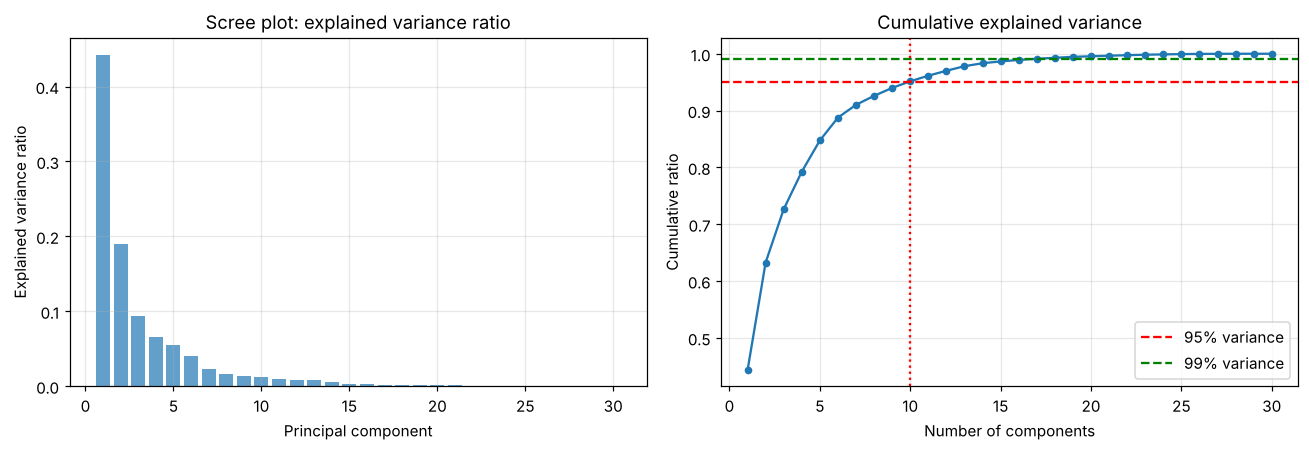

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(range(1, 31), evr, alpha=.7); ax[0].set_title("Scree plot: explained variance ratio")
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance ratio")
ax[1].plot(range(1, 31), cum, "o-", ms=4)
for thr, c in [(.95, "r"), (.99, "g")]:
    ax[1].axhline(thr, ls="--", c=c, label=f"{int(thr*100)}% variance")
ax[1].axvline(n95, ls=":", c="r"); ax[1].set_title("Cumulative explained variance")
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative ratio"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. LDA: maximum class separation (supervised)
LDA maximises the Fisher criterion $J(w)=\dfrac{(\mu_1-\mu_0)^2}{s_0^2+s_1^2}$ (between-class scatter / within-class scatter). For $C$ classes it can give at most $\min(C-1,\,d)$ components, so with **2 classes the answer is exactly 1 component**.

Max LDA components = min(C-1, d) = 1 | output shape: (569, 1)
Class means on LD1 : malignant -2.40 | benign 1.43
Fisher ratio       : 6.58
Silhouette (labels): 0.678
Training accuracy of LDA classifier: 0.9649


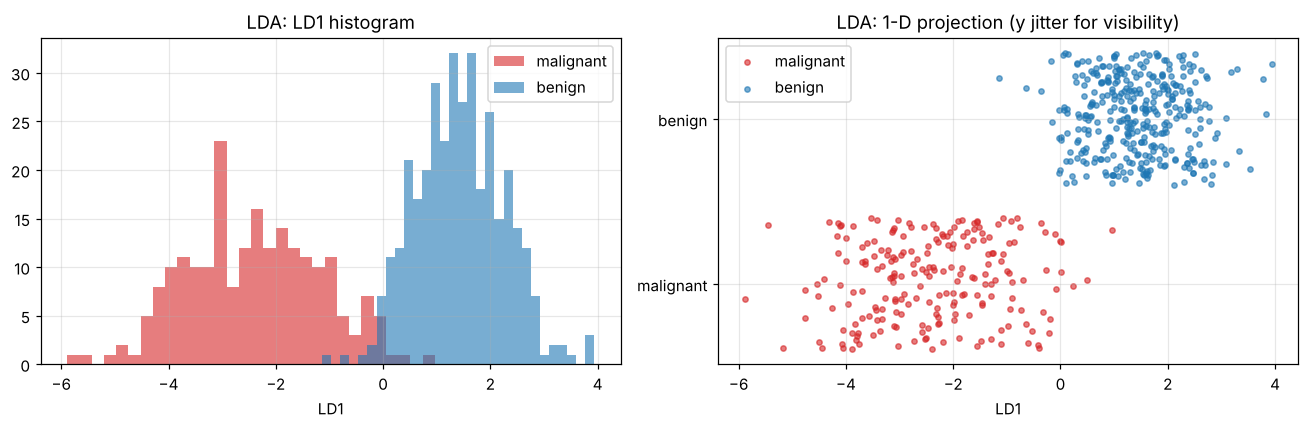

In [5]:
n_lda = min(len(target_names) - 1, Xs.shape[1])
t = time.perf_counter()
lda = LDA(n_components=n_lda); Z_lda = lda.fit_transform(Xs, y)
t_lda = time.perf_counter() - t

m0, m1 = Z_lda[y == 0].mean(), Z_lda[y == 1].mean()
fisher = (m0 - m1)**2 / (Z_lda[y == 0].var() + Z_lda[y == 1].var())
print("Max LDA components = min(C-1, d) =", n_lda, "| output shape:", Z_lda.shape)
print("Class means on LD1 : malignant %.2f | benign %.2f" % (m0, m1))
print("Fisher ratio       : %.2f" % fisher)
print("Silhouette (labels): %.3f" % silhouette_score(Z_lda, y))
print("Training accuracy of LDA classifier: %.4f" % lda.score(Xs, y))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c in (0, 1):
    ax[0].hist(Z_lda[y == c, 0], bins=30, alpha=.6, color=COLORS[c], label=target_names[c])
ax[0].set_title("LDA: LD1 histogram"); ax[0].set_xlabel("LD1"); ax[0].legend()
rng = np.random.default_rng(0)
for c in (0, 1):
    ax[1].scatter(Z_lda[y == c, 0], rng.uniform(-.4, .4, (y == c).sum()) + c, s=12, alpha=.6, c=COLORS[c], label=target_names[c])
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["malignant", "benign"]); ax[1].set_xlabel("LD1")
ax[1].set_title("LDA: 1-D projection (y jitter for visibility)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. ICA: statistical independence (unsupervised)
ICA (FastICA) first whitens the data, then finds a rotation that makes the components as **non-Gaussian** (hence statistically independent) as possible, by maximising negentropy/kurtosis.

In [6]:
t = time.perf_counter()
ica2 = FastICA(n_components=2, whiten="unit-variance", max_iter=3000, random_state=42)
Z_ica = ica2.fit_transform(Xs)
t_ica = time.perf_counter() - t
print("Reduced dimensions (ICA):", Z_ica.shape, "| iterations:", ica2.n_iter_)
print("Mixing matrix shape     :", ica2.mixing_.shape, "(features x components)")

Reduced dimensions (ICA): (569, 2) | iterations: 5
Mixing matrix shape     : (30, 2) (features x components)


## 6. Visualise all transformed data

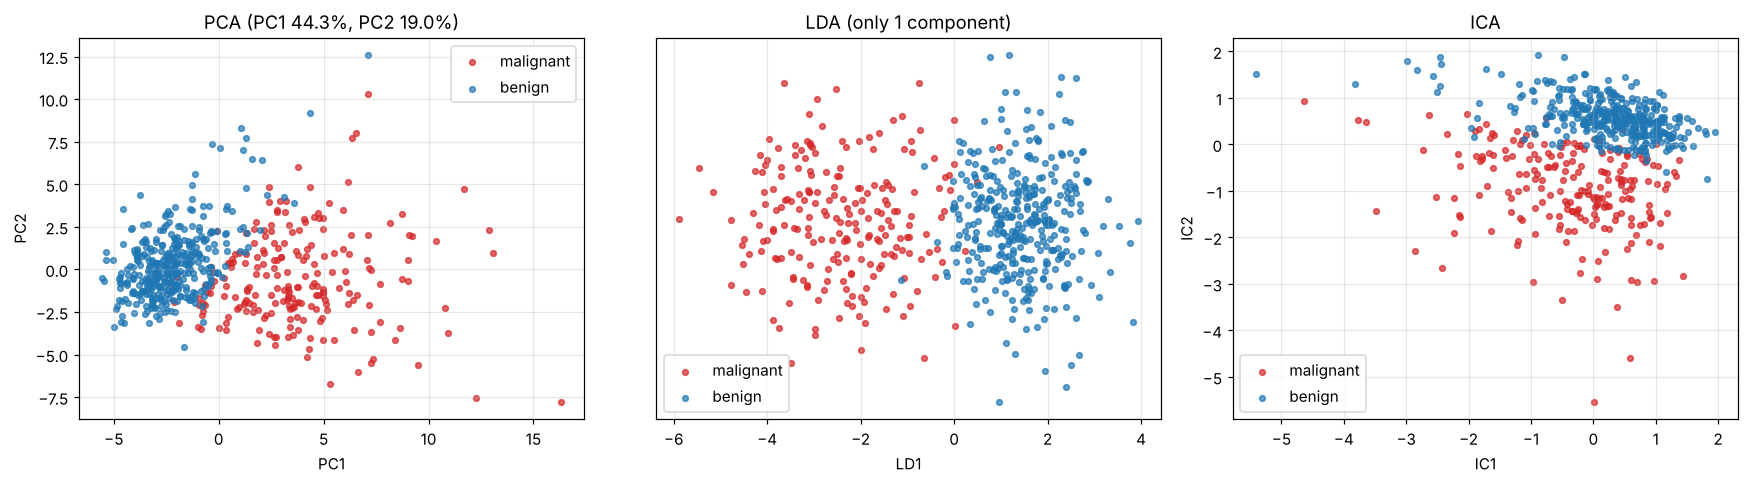

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for c in (0, 1):
    m = y == c
    ax[0].scatter(Z_pca[m, 0], Z_pca[m, 1], s=14, alpha=.7, c=COLORS[c], label=target_names[c])
    ax[2].scatter(Z_ica[m, 0], Z_ica[m, 1], s=14, alpha=.7, c=COLORS[c], label=target_names[c])
    ax[1].scatter(Z_lda[m, 0], rng.normal(0, .05, m.sum()), s=14, alpha=.7, c=COLORS[c], label=target_names[c])
ax[0].set(title=f"PCA (PC1 {evr[0]*100:.1f}%, PC2 {evr[1]*100:.1f}%)", xlabel="PC1", ylabel="PC2")
ax[1].set(title="LDA (only 1 component)", xlabel="LD1", yticks=[])
ax[2].set(title="ICA", xlabel="IC1", ylabel="IC2")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

### 6b. Examine the independent components (ICA)
Independence is checked two ways: (i) the components are uncorrelated, (ii) they are non-Gaussian (excess kurtosis far from 0 and a skewed histogram).

Correlation matrix of ICs:
 [[ 1. -0.]
 [-0.  1.]]
Excess kurtosis of ICs   : [2.92 2.46]  (Gaussian = 0)


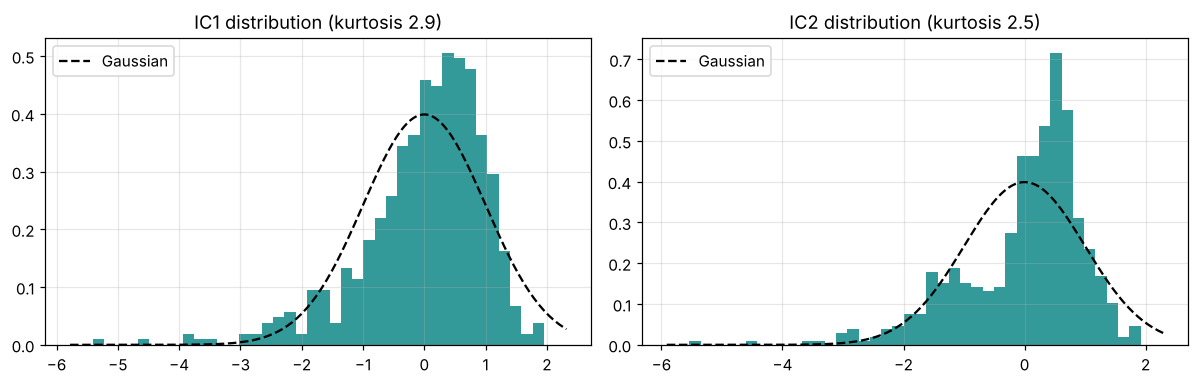

In [8]:
print("Correlation matrix of ICs:\n", np.corrcoef(Z_ica.T).round(4))
print("Excess kurtosis of ICs   :", kurtosis(Z_ica, axis=0).round(2), " (Gaussian = 0)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i in range(2):
    ax[i].hist(Z_ica[:, i], bins=40, color="teal", alpha=.8, density=True)
    xs = np.linspace(*ax[i].get_xlim(), 200)
    ax[i].plot(xs, np.exp(-xs**2/2)/np.sqrt(2*np.pi), "k--", label="Gaussian")
    ax[i].set_title(f"IC{i+1} distribution (kurtosis {kurtosis(Z_ica[:, i]):.1f})"); ax[i].legend()
plt.tight_layout(); plt.show()

## 7. Compare the number of components

In [9]:
comp = pd.DataFrame({
    "Technique": ["Original", "PCA", "LDA", "ICA"],
    "Max possible components": [30, 30, "min(C-1, d) = 1", 30],
    "Components used in this lab": [30, f"2 (95% variance needs {n95})", 1, 2],
    "Output shape": [X.shape, Z_pca.shape, Z_lda.shape, Z_ica.shape],
}).set_index("Technique"); comp

,Max possible components,Components used in this lab,Output shape
Technique,,,
Original,30,30,"(569, 30)"
PCA,30,2 (95% variance needs 10),"(569, 2)"
LDA,"min(C-1, d) = 1",1,"(569, 1)"
ICA,30,2,"(569, 2)"


## 8. Variance retained (PCA) and class separation (LDA)

In [10]:
Z_full = PCA(n_components=n95).fit(Xs)
recon = Z_full.inverse_transform(Z_full.transform(Xs))
print(f"PCA with {n95} components keeps {cum[n95-1]*100:.2f}% of variance "
      f"(reduction: 30 -> {n95}, {100*(1-n95/30):.0f}% fewer features)")
print("Reconstruction MSE (standardised units): %.4f" % np.mean((Xs - recon)**2))

PCA with 10 components keeps 95.16% of variance (reduction: 30 -> 10, 67% fewer features)
Reconstruction MSE (standardised units): 0.0484


## 9. Comparative analysis (computed, not just quoted)
Separation is judged with the silhouette score (true labels) and with a downstream **logistic-regression classifier under 5-fold stratified CV**. The scaler and reducer are fitted *inside* each fold using a `Pipeline`, so no information leaks from the test fold.

In [11]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
def cv_acc(reducer):
    return cross_val_score(make_pipeline(StandardScaler(), reducer, LogisticRegression(max_iter=2000)), X, y, cv=cv).mean()

acc_pca = cv_acc(PCA(n_components=2))
acc_lda = cv_acc(LDA(n_components=1))
acc_ica = cv_acc(FastICA(n_components=2, whiten="unit-variance", max_iter=3000, random_state=42))
acc_raw = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, y, cv=cv).mean()

table = pd.DataFrame({
    "Parameter": ["Approach", "Primary objective", "Uses class labels", "Main output",
                  "Components in this lab", "Fit time (s)", "Silhouette (true labels)",
                  "5-fold CV accuracy", "Common applications"],
    "PCA": ["Unsupervised", "Maximum variance", "No", "Principal components", 2, f"{t_pca:.4f}",
            f"{silhouette_score(Z_pca, y):.3f}", f"{acc_pca:.4f}", "Data compression"],
    "LDA": ["Supervised", "Maximum class separation", "Yes", "Discriminant components", 1, f"{t_lda:.4f}",
            f"{silhouette_score(Z_lda, y):.3f}", f"{acc_lda:.4f}", "Classification"],
    "ICA": ["Unsupervised", "Statistical independence", "No", "Independent components", 2, f"{t_ica:.4f}",
            f"{silhouette_score(Z_ica, y):.3f}", f"{acc_ica:.4f}", "Signal processing"],
}).set_index("Parameter")
print("Baseline (all 30 features, LogReg): %.4f" % acc_raw)
table

Baseline (all 30 features, LogReg): 0.9737


,PCA,LDA,ICA
Parameter,,,
Approach,Unsupervised,Supervised,Unsupervised
Primary objective,Maximum variance,Maximum class separation,Statistical independence
Uses class labels,No,Yes,No
Main output,Principal components,Discriminant components,Independent components
Components in this lab,2,1,2
Fit time (s),0.0013,0.0023,0.0021
Silhouette (true labels),0.438,0.678,0.374
5-fold CV accuracy,0.9473,0.9684,0.9403
Common applications,Data compression,Classification,Signal processing


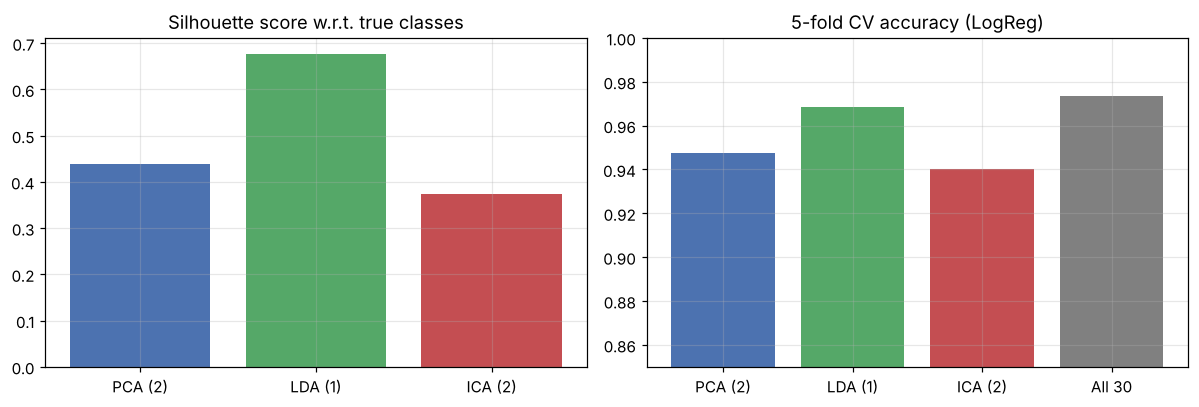

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
names_ = ["PCA (2)", "LDA (1)", "ICA (2)"]
ax[0].bar(names_, [silhouette_score(Z, y) for Z in (Z_pca, Z_lda, Z_ica)], color=["#4c72b0", "#55a868", "#c44e52"])
ax[0].set_title("Silhouette score w.r.t. true classes")
ax[1].bar(names_ + ["All 30"], [acc_pca, acc_lda, acc_ica, acc_raw], color=["#4c72b0", "#55a868", "#c44e52", "gray"])
ax[1].set_ylim(.85, 1); ax[1].set_title("5-fold CV accuracy (LogReg)")
plt.tight_layout(); plt.show()

---
## 10. Self-learning extension (beyond the lab sheet)
The lab sheet stops at "run the three techniques". These extras answer questions a good practitioner would ask next.

| # | Extension | Question answered |
|---|---|---|
| A | Accuracy vs number of components | How many components do we actually need? |
| B | PCA loadings | What do PC1/PC2 physically mean? |
| C | PCA reconstruction error | What is lost when we compress? |
| D | Data-leakage demo | Why must LDA/PCA be fitted inside CV folds? |
| E | Blind source separation | Where does ICA really work (and why is it weak on this dataset)? |

### A. How many components are enough?

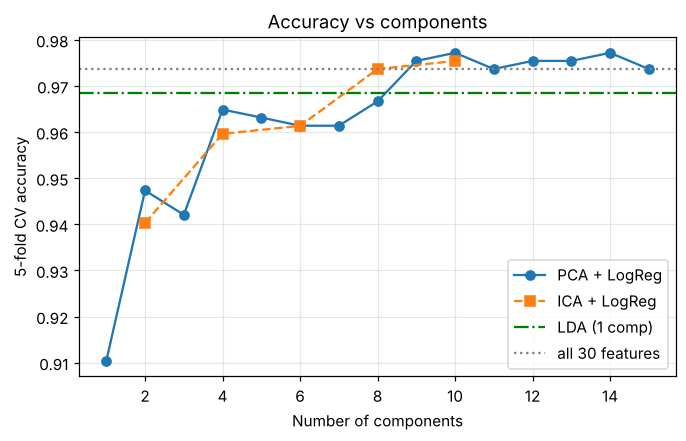

PCA needs about 4 components to match the 30-feature baseline within 1%.


In [13]:
ks = list(range(1, 16))
accs = [cv_acc(PCA(n_components=k)) for k in ks]
ica_ks = [2, 4, 6, 8, 10]
ica_accs = [cv_acc(FastICA(n_components=k, whiten="unit-variance", max_iter=3000, random_state=42)) for k in ica_ks]
plt.figure(figsize=(7, 4))
plt.plot(ks, accs, "o-", label="PCA + LogReg")
plt.plot(ica_ks, ica_accs, "s--", label="ICA + LogReg")
plt.axhline(acc_lda, c="g", ls="-.", label="LDA (1 comp)")
plt.axhline(acc_raw, c="gray", ls=":", label="all 30 features")
plt.xlabel("Number of components"); plt.ylabel("5-fold CV accuracy"); plt.legend(); plt.title("Accuracy vs components")
plt.show()
print("PCA needs about %d components to match the 30-feature baseline within 1%%." %
      next(k for k, a in zip(ks, accs) if a >= acc_raw - 0.01))

### B. What do the principal components mean? (loadings)

,PC1,PC2
mean concave points,0.261,-0.035
mean concavity,0.258,0.060
worst concave points,0.251,-0.008
mean compactness,0.239,0.152
worst perimeter,0.237,-0.200
worst concavity,0.229,0.098
worst radius,0.228,-0.220
mean perimeter,0.228,-0.215


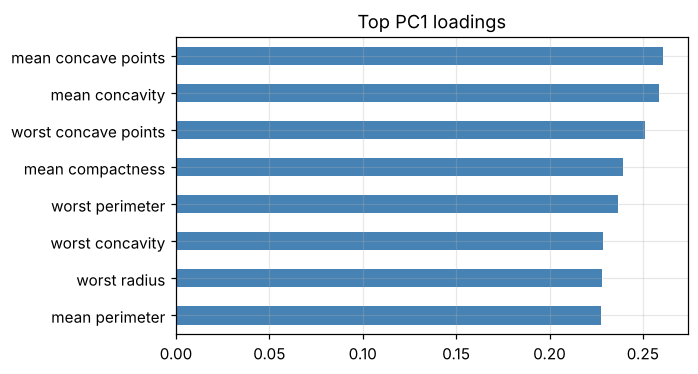

Reading: PC1 loads with the same sign on concavity / concave points / compactness AND on radius / perimeter,
so PC1 is an overall 'tumour size + shape irregularity' axis, which is why it already separates malignant from benign.
PC2 contrasts size features (negative) with compactness/texture-type features (positive).


In [14]:
load = pd.DataFrame(pca_full.components_[:2].T, index=feature_names, columns=["PC1", "PC2"])
top = load.reindex(load["PC1"].abs().sort_values(ascending=False).index).head(8)
display(top.round(3))
top["PC1"][::-1].plot.barh(figsize=(6, 3.5), color="steelblue", title="Top PC1 loadings")
plt.show()
print("Reading: PC1 loads with the same sign on concavity / concave points / compactness AND on radius / perimeter,")
print("so PC1 is an overall 'tumour size + shape irregularity' axis, which is why it already separates malignant from benign.")
print("PC2 contrasts size features (negative) with compactness/texture-type features (positive).")

### C. Compression trade-off: reconstruction error vs components

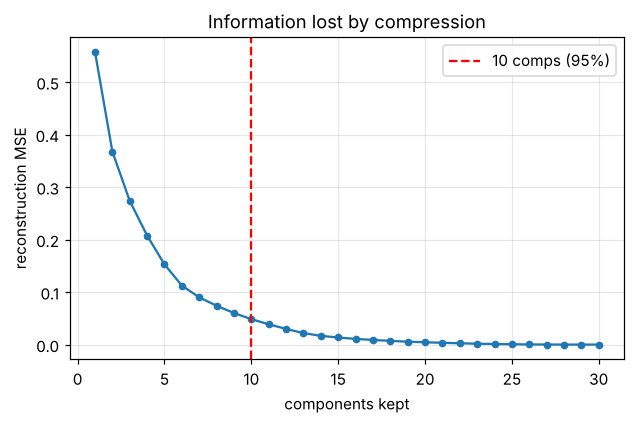

In [15]:
errs = [np.mean((Xs - PCA(n_components=k).fit(Xs).inverse_transform(PCA(n_components=k).fit(Xs).transform(Xs)))**2) for k in range(1, 31)]
plt.figure(figsize=(6.5, 3.8)); plt.plot(range(1, 31), errs, "o-", ms=4)
plt.axvline(n95, c="r", ls="--", label=f"{n95} comps (95%)"); plt.xlabel("components kept")
plt.ylabel("reconstruction MSE"); plt.title("Information lost by compression"); plt.legend(); plt.show()

### D. Data leakage: why fit LDA inside cross-validation
LDA uses labels. If we fit it on **all** data and then cross-validate a classifier on the projected data, the test labels have already influenced the projection, and accuracy is **optimistically biased**. The pipeline numbers above avoid this. Below we show the difference.

In [16]:
Z_leaky = LDA(n_components=1).fit_transform(Xs, y)          # labels of ALL samples used
leaky = cross_val_score(LogisticRegression(), Z_leaky, y, cv=cv).mean()
print("LDA accuracy, LEAKY  (fit on all data): %.4f" % leaky)
print("LDA accuracy, honest (inside pipeline): %.4f" % acc_lda)
print("Optimism due to leakage              : %+.4f" % (leaky - acc_lda))
print("(With only 1 output dimension on 569 samples the bias is small here, but it grows with more classes/fewer samples.)")

LDA accuracy, LEAKY  (fit on all data): 0.9754
LDA accuracy, honest (inside pipeline): 0.9684
Optimism due to leakage              : +0.0070
(With only 1 output dimension on 569 samples the bias is small here, but it grows with more classes/fewer samples.)


### E. Blind source separation: the real home of ICA
ICA assumes the observed data are a *linear mixture of independent, non-Gaussian sources*. That is true for audio/EEG, not for tumour measurements (they are correlated size features, not independent sources). So ICA is expected to do **worse than PCA/LDA** on the breast-cancer data, while it excels on the classic "cocktail party" problem below.

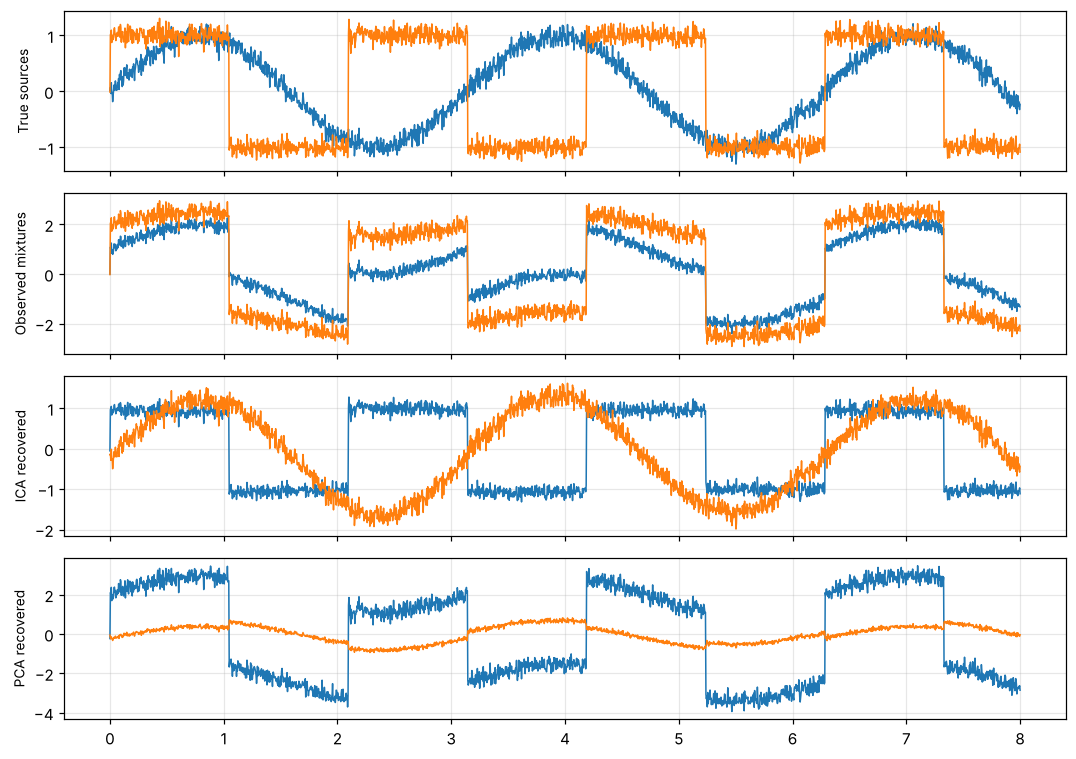

Max |corr| of each true source with an ICA output: [0.998 1.   ] (1.0 = perfect recovery)
Max |corr| of each true source with a PCA output : [0.934 0.962]


In [17]:
tt = np.linspace(0, 8, 2000)
S = np.c_[np.sin(2*tt), np.sign(np.sin(3*tt))] + 0.1*np.random.default_rng(0).normal(size=(2000, 2))
Mx = S @ np.array([[1, 1], [0.5, 2]]).T                     # two microphones, each hears a mixture
S_ica = FastICA(n_components=2, random_state=0, whiten="unit-variance").fit_transform(Mx)
S_pca = PCA(n_components=2).fit_transform(Mx)
fig, axs = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for a, d, t_ in zip(axs, [S, Mx, S_ica, S_pca], ["True sources", "Observed mixtures", "ICA recovered", "PCA recovered"]):
    a.plot(tt, d, lw=1); a.set_ylabel(t_, fontsize=9)
plt.tight_layout(); plt.show()
corr = np.abs(np.corrcoef(S.T, S_ica.T)[:2, 2:])
print("Max |corr| of each true source with an ICA output:", corr.max(1).round(3), "(1.0 = perfect recovery)")
corr = np.abs(np.corrcoef(S.T, S_pca.T)[:2, 2:])
print("Max |corr| of each true source with a PCA output :", corr.max(1).round(3))

---
## 11. Analysis and Discussion

**1. What is dimensionality reduction and why is it important?**
It maps data from $d$ dimensions to $k<d$ dimensions while keeping as much useful structure as possible. It matters because it (i) fights the *curse of dimensionality* (distances become meaningless, data becomes sparse), (ii) removes redundant/correlated features (here radius, perimeter and area are almost the same information), (iii) reduces overfitting, memory and training time, (iv) enables 2-D/3-D visualisation, and (v) can denoise the data.

**2. Fundamental differences between PCA, LDA and ICA**

| | PCA | LDA | ICA |
|---|---|---|---|
| Learning type | Unsupervised | Supervised | Unsupervised |
| Objective | Maximise variance | Maximise between-class / within-class scatter | Maximise statistical independence (non-Gaussianity) |
| Components | Orthogonal, ordered by variance | At most $C-1$ | Not orthogonal in general, unordered, sign/scale ambiguous |
| Statistics used | 2nd order (covariance) | Class means + covariances | Higher-order (kurtosis / negentropy) |
| Typical use | Compression, visualisation | Classification | Blind source separation |

**3. Why does PCA focus on variance rather than class separation?**
PCA never sees the labels. Its assumption is that directions with large variance carry the signal and low-variance directions are noise. High variance does *not* guarantee class separation: a high-variance direction can be identical for both classes. It only works for classification when the class difference happens to lie along the high-variance directions (as it largely does here via tumour size).

**4. How does LDA use class labels?**
It computes class means and the within-class scatter $S_W$ and between-class scatter $S_B$, then finds $w$ maximising $\dfrac{w^TS_Bw}{w^TS_Ww}$, i.e. the generalised eigenproblem $S_W^{-1}S_Bw=\lambda w$. The projection pushes class means apart and squeezes each class together. With 2 classes the rank of $S_B$ is 1, hence only 1 component.

**5. Why does ICA look for statistically independent components?**
It models observations as $x = A s$ with independent sources $s$. Independence is stronger than being uncorrelated (PCA only de-correlates), and by the central limit theorem a mixture of sources is *more Gaussian* than the sources themselves, so maximising non-Gaussianity un-mixes them. This needs at most one Gaussian source.

**6. Which technique gives the best class separation here? (justify)**
**LDA.** Compare the numbers in section 9: LDA with a **single** component has the highest silhouette score (about 0.68 vs 0.44 for PCA and 0.37 for ICA) and the highest cross-validated accuracy of the three (about 96.8% vs 94.7% PCA and 94.0% ICA, against 97.4% for all 30 features), because it is the only method that optimises for the labels. PCA is second (tumour size already differs between classes, and PC1 captures it) but needs more components to approach LDA. ICA is weakest because independence is not related to class membership and the features are not independent sources.

**7. Real-world applications**
- **PCA:** image/data compression, noise reduction, visualisation of gene expression, finance (yield-curve factors), preprocessing before regression/clustering.
- **LDA:** face recognition (Fisherfaces), medical diagnosis, credit-risk and bankruptcy classification, document/topic classification.
- **ICA:** EEG/MEG artefact (eye-blink) removal, cocktail-party speech separation, fMRI analysis, financial time-series factor discovery, image feature extraction.

**Limitations to mention in the viva:** all three are *linear*; LDA assumes Gaussian classes with a shared covariance; ICA results depend on random initialisation (set `random_state`) and have sign/order ambiguity; for non-linear structure use Kernel PCA, t-SNE or UMAP.

---
## 12. Streamlit dashboard (implemented from the notebook)
The cell below uses `%%writefile` to generate `app.py` straight from the notebook, so the notebook is the single source of the app. The dashboard contains tabs for Dataset / PCA / LDA / ICA / Comparison, interactive sliders (number of components, variance target, seed, scaling on/off) and the blind-source-separation bonus demo.

In [18]:
%%writefile app.py
"""
Lab Exercise 4 - Interactive Streamlit dashboard
Comparative Analysis of PCA, LDA and ICA on the Breast Cancer Wisconsin dataset.
Run with:  streamlit run app.py
"""
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st
from scipy.stats import kurtosis
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FastICA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score

st.set_page_config(page_title="PCA vs LDA vs ICA", layout="wide")
COLORS = {0: "#d62728", 1: "#1f77b4"}  # 0 = malignant, 1 = benign


@st.cache_data
def load():
    d = load_breast_cancer()
    return pd.DataFrame(d.data, columns=d.feature_names), d.target, list(d.target_names)


X_df, y, names = load()
X = X_df.values

st.title("Comparative Analysis of PCA, LDA and ICA")
st.caption("Breast Cancer Wisconsin dataset  |  MAI511-2 Advanced Machine Learning  |  Lab Exercise 4")

# ---------------- sidebar ----------------
st.sidebar.header("Controls")
scale = st.sidebar.checkbox("Standardise features (recommended)", True)
n_pca = st.sidebar.slider("PCA components", 2, 30, 2)
n_ica = st.sidebar.slider("ICA components", 2, 30, 2)
var_target = st.sidebar.slider("Variance target for PCA (%)", 50, 99, 95)
seed = st.sidebar.number_input("Random seed (ICA)", 0, 999, 42)

Xs = StandardScaler().fit_transform(X) if scale else X

# ---------------- fit ----------------
t = time.perf_counter(); pca_full = PCA().fit(Xs); t_pca = time.perf_counter() - t
Z_pca = PCA(n_components=n_pca).fit_transform(Xs)
t = time.perf_counter(); Z_lda = LDA(n_components=1).fit_transform(Xs, y); t_lda = time.perf_counter() - t
t = time.perf_counter()
ica = FastICA(n_components=n_ica, whiten="unit-variance", max_iter=3000, random_state=int(seed))
Z_ica = ica.fit_transform(Xs); t_ica = time.perf_counter() - t

evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
k_target = int(np.searchsorted(cum, var_target / 100) + 1)

tab1, tab2, tab3, tab4, tab5 = st.tabs(
    ["Dataset", "PCA", "LDA", "ICA", "Comparison"])

# ---------------- tab 1 ----------------
with tab1:
    c1, c2, c3 = st.columns(3)
    c1.metric("Samples", X.shape[0])
    c2.metric("Features", X.shape[1])
    c3.metric("Malignant / Benign", f"{(y==0).sum()} / {(y==1).sum()}")
    st.dataframe(X_df.head(10))
    st.write("**Why standardise?** Features such as `area` (hundreds to thousands) dwarf "
             "`smoothness` (~0.1). PCA/ICA would be dominated by the large-scale features.")

# ---------------- tab 2 ----------------
with tab2:
    c1, c2 = st.columns(2)
    fig, ax = plt.subplots(figsize=(5, 4))
    for c in (0, 1):
        ax.scatter(Z_pca[y == c, 0], Z_pca[y == c, 1], s=14, alpha=.7, c=COLORS[c], label=names[c])
    ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
    ax.set_title("PCA projection"); ax.legend()
    c1.pyplot(fig)

    fig, ax = plt.subplots(figsize=(5, 4))
    ax.bar(range(1, 31), evr, alpha=.6, label="individual")
    ax.step(range(1, 31), cum, where="mid", c="k", label="cumulative")
    ax.axhline(var_target / 100, ls="--", c="r")
    ax.set_xlabel("Component"); ax.set_ylabel("Explained variance ratio"); ax.legend()
    ax.set_title("Scree + cumulative variance")
    c2.pyplot(fig)
    st.success(f"{k_target} components are needed to retain {var_target}% of the variance "
               f"(from 30 original features). First two PCs keep {cum[1]*100:.2f}%.")

    with st.expander("What do PC1 and PC2 mean? (loadings)"):
        load_df = pd.DataFrame(pca_full.components_[:2].T, index=X_df.columns, columns=["PC1", "PC2"])
        st.dataframe(load_df.reindex(load_df["PC1"].abs().sort_values(ascending=False).index).head(10))

# ---------------- tab 3 ----------------
with tab3:
    st.write("With 2 classes LDA can produce at most **min(n_classes-1, n_features) = 1** component.")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for c in (0, 1):
        ax.hist(Z_lda[y == c, 0], bins=30, alpha=.6, color=COLORS[c], label=names[c])
    ax.set_xlabel("LD1"); ax.set_ylabel("count"); ax.legend(); ax.set_title("LDA projection (1-D)")
    st.pyplot(fig)
    m0, m1 = Z_lda[y == 0].mean(), Z_lda[y == 1].mean()
    fisher = (m0 - m1) ** 2 / (Z_lda[y == 0].var() + Z_lda[y == 1].var())
    c1, c2 = st.columns(2)
    c1.metric("Fisher ratio (between / within)", f"{fisher:.2f}")
    c2.metric("Silhouette (true labels)", f"{silhouette_score(Z_lda, y):.3f}")

# ---------------- tab 4 ----------------
with tab4:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for c in (0, 1):
        axes[0].scatter(Z_ica[y == c, 0], Z_ica[y == c, 1], s=14, alpha=.7, c=COLORS[c], label=names[c])
    axes[0].set_xlabel("IC1"); axes[0].set_ylabel("IC2"); axes[0].set_title("ICA projection"); axes[0].legend()
    k = kurtosis(Z_ica, axis=0)  # excess kurtosis, 0 for a Gaussian
    axes[1].bar(range(1, n_ica + 1), k, color="teal")
    axes[1].set_xlabel("Independent component"); axes[1].set_ylabel("Excess kurtosis")
    axes[1].set_title("Non-Gaussianity (ICA maximises this)")
    st.pyplot(fig)
    corr = np.corrcoef(Z_ica.T)
    off = np.abs(corr - np.eye(n_ica)).max()
    st.write(f"Max |correlation| between different ICs: **{off:.2e}** (uncorrelated, as expected after whitening).")
    st.caption("ICA components have no natural order or sign, unlike PCA; they are only unique up to permutation/sign/scale.")

# ---------------- tab 5 ----------------
with tab5:
    cv = StratifiedKFold(5, shuffle=True, random_state=42)

    def acc(reducer):
        pipe = make_pipeline(StandardScaler(), reducer, LogisticRegression(max_iter=2000))
        return cross_val_score(pipe, X, y, cv=cv).mean()

    with st.spinner("Cross-validating (leak-free pipelines)..."):
        a_pca = acc(PCA(n_components=n_pca))
        a_lda = acc(LDA(n_components=1))
        a_ica = acc(FastICA(n_components=n_ica, whiten="unit-variance", max_iter=3000, random_state=int(seed)))
        a_raw = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, y, cv=cv).mean()

    table = pd.DataFrame({
        "Parameter": ["Approach", "Objective", "Uses labels", "Components produced",
                      "Fit time (s)", "Silhouette (true labels)", "5-fold CV accuracy (LogReg)",
                      "Typical use"],
        "PCA": ["Unsupervised", "Max variance", "No", n_pca, f"{t_pca:.4f}",
                f"{silhouette_score(Z_pca, y):.3f}", f"{a_pca:.4f}", "Compression / visualisation"],
        "LDA": ["Supervised", "Max class separation", "Yes", 1, f"{t_lda:.4f}",
                f"{silhouette_score(Z_lda, y):.3f}", f"{a_lda:.4f}", "Classification"],
        "ICA": ["Unsupervised", "Statistical independence", "No", n_ica, f"{t_ica:.4f}",
                f"{silhouette_score(Z_ica, y):.3f}", f"{a_ica:.4f}", "Signal processing / BSS"],
    }).astype(str).set_index("Parameter")
    st.table(table)
    st.info(f"Baseline: logistic regression on all 30 standardised features = {a_raw:.4f}")
    best = max([("PCA", a_pca), ("LDA", a_lda), ("ICA", a_ica)], key=lambda p: p[1])
    st.success(f"Best class separation for this dataset with current settings: **{best[0]}** ({best[1]:.4f}).")

# ---------------- bonus: cocktail party ----------------
st.divider()
st.header("Bonus: where ICA really shines (blind source separation)")
st.write("Two independent signals are mixed by two 'microphones'. PCA can only de-correlate; "
         "ICA recovers the original sources.")
tt = np.linspace(0, 8, 2000)
S = np.c_[np.sin(2 * tt), np.sign(np.sin(3 * tt))]
S += 0.1 * np.random.default_rng(0).normal(size=S.shape)
M = S @ np.array([[1, 1], [0.5, 2]]).T
S_ica = FastICA(n_components=2, random_state=0, whiten="unit-variance").fit_transform(M)
S_pca = PCA(n_components=2).fit_transform(M)
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for ax, d, tl in zip(axes, [S, M, S_ica, S_pca],
                     ["True sources", "Observed mixtures", "ICA recovered", "PCA recovered"]):
    ax.plot(tt, d, lw=1); ax.set_ylabel(tl, fontsize=9)
plt.tight_layout()
st.pyplot(fig)

Overwriting app.py


### Run the Streamlit app
**Locally (VS Code / Jupyter):** `pip install streamlit` then run in a terminal: `streamlit run app.py`

**On Google Colab:** run the next cell, then open the printed `https://xxxx.loca.lt` link (the password it asks for is the IP printed by the first command).

In [19]:
# --- Google Colab / hosted notebook launcher (skip if running locally) ---
# !pip install -q streamlit
# !npm install -q localtunnel
# !streamlit run app.py &>/content/logs.txt &
# !curl -s ipv4.icanhazip.com        # copy this IP: it is the tunnel password
# !npx localtunnel --port 8501